Create dataset and upload to Hugging Face

In [1]:
!pip install datasets
!cd /content/
!git clone https://github.com/huggingface/diffusers.git
!pip install ./diffusers
!pip install -U -r /content/diffusers/examples/text_to_image/requirements.txt
!pip install bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.1/316.1 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.9/39.9 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 13.5 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 14.0.2
    Uninstalling pyarrow-14.0.2:
      Successfully uninstalled pyarrow-14.0.2
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2024.6.1
    Uninstalling fsspec-2024.6.1:
      Successfully uninstalled fsspec-2024.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.3.1+cu121 requir

In [2]:
from datasets import load_dataset
from google.colab import drive
import zipfile
import os
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset
import csv
from huggingface_hub import notebook_login
import torch
from diffusers import StableDiffusionPipeline

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [7]:
torch.__version__

'2.4.0+cu121'

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Path to the dataset zip file
zip_file_path = './drive/MyDrive/nuclear_fuel_bundle_dataset_2.zip'

# Subfolder to extract
subfolder = 'data/'

# Destination directory to extract files
destination_dir = './nuclear_fuel_bundle'

# Create the destination directory if it doesn't exist
os.makedirs(destination_dir, exist_ok=True)

# Open the zip file and extract only the taget subfolder
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    for member in zip_ref.namelist():
        if member.startswith(subfolder):
            zip_ref.extract(member, destination_dir)

            extracted_path = os.path.join(destination_dir, member)

            new_path = os.path.join(destination_dir, os.path.basename(member))
            os.rename(extracted_path, new_path)

            # Remove any empty directories that may have been created
            if os.path.isdir(os.path.dirname(extracted_path)):
                os.rmdir(os.path.dirname(extracted_path))


In [ ]:
class AugmentedDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        self.img_names = os.listdir(img_dir)

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image

# Define your data augmentation transformations
data_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    #transforms.RandomVerticalFlip(p=0.5),
    #transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2),
    transforms.RandomResizedCrop(size=(256, 256), scale=(0.8, 1.0)),
])

# Create the dataset with transformations
augmented_dataset = AugmentedDataset(img_dir=destination_dir, transform=data_transforms)

# Function to save a single augmented image per original image
def save_augmented_images(dataset, output_dir="augmented_images"):
    os.makedirs(output_dir, exist_ok=True)
    for i, img_name in enumerate(dataset.img_names):
        image = dataset[i]
        image.save(f"{output_dir}/{img_name}")
        print(f"Processed and saved augmented image {i + 1}/{len(dataset.img_names)}")

# Example usage
save_augmented_images(augmented_dataset, output_dir='./augmented_nuclear_fuel_bundle_2')


Processed and saved augmented image 1/303
Processed and saved augmented image 2/303
Processed and saved augmented image 3/303
Processed and saved augmented image 4/303
Processed and saved augmented image 5/303
Processed and saved augmented image 6/303
Processed and saved augmented image 7/303
Processed and saved augmented image 8/303
Processed and saved augmented image 9/303
Processed and saved augmented image 10/303
Processed and saved augmented image 11/303
Processed and saved augmented image 12/303
Processed and saved augmented image 13/303
Processed and saved augmented image 14/303
Processed and saved augmented image 15/303
Processed and saved augmented image 16/303
Processed and saved augmented image 17/303
Processed and saved augmented image 18/303
Processed and saved augmented image 19/303
Processed and saved augmented image 20/303
Processed and saved augmented image 21/303
Processed and saved augmented image 22/303
Processed and saved augmented image 23/303
Processed and saved 

UnidentifiedImageError: cannot identify image file './nuclear_fuel_bundle/metadata.csv'

In [ ]:
# Output metadata file path
output_file_path = './augmented_nuclear_fuel_bundle/metadata.csv'

def write_metadata(folder_path, output_path, description):
  # Create and open the output CSV file
  with open(output_file_path, 'w', newline='') as csvfile:
      csvwriter = csv.writer(csvfile)

      # Write the header
      csvwriter.writerow(["file_name", "text"])

      # Iterate through each jpg in the directory
      for filename in os.listdir(destination_dir):
          if filename.endswith('.jpg') or filename.endswith('.png')or filename.endswith('.jpeg'):
              # Write the file name and the description
              csvwriter.writerow([filename, description])

write_metadata('./augmented_nuclear_fuel_bundle', output_file_path, "nuclear fuel bundle")

Require manual labeling

In [ ]:
notebook_login()  #login to huggingface

In [ ]:
# load and push dataset to Hugging Face
dataset = load_dataset("imagefolder", data_dir="./augmented_nuclear_fuel_bundle_2", drop_labels=True)

dataset.push_to_hub("vinayakgoyal/augmented_nuclear_fuel_bundle_dataset_2")

Resolving data files:   0%|          | 0/168 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/167 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

CommitInfo(commit_url='https://huggingface.co/datasets/vinayakgoyal/augmented_nuclear_fuel_bundle_dataset_2/commit/730b21e80566071545f64f2dfb6b4ba8a827a639', commit_message='Upload dataset', commit_description='', oid='730b21e80566071545f64f2dfb6b4ba8a827a639', pr_url=None, pr_revision=None, pr_num=None)

Finetune Stable Diffusion Model

In [ ]:
!nvidia-smi

Wed Jul 31 18:39:36 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   41C    P8               9W /  70W |      3MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [ ]:
!accelerate config default --mixed_precision fp16

accelerate configuration saved at /root/.cache/huggingface/accelerate/default_config.yaml


In [ ]:
torch.cuda.empty_cache()  #Clear cache before training

In [ ]:
# Define paths
os.environ['MODEL_NAME'] = f'CompVis/stable-diffusion-v1-4'
os.environ['DATASET_NAME'] = f'vinayakgoyal/augmented_nuclear_fuel_bundle_dataset_2'
os.environ['OUTPUT_DIR'] = f'nuclear_fuel_bundle-model-v1-4_augmented_5000_1'

In [ ]:
# using 8bit_adam due to limited memory
!accelerate launch diffusers/examples/text_to_image/train_text_to_image.py \
  --pretrained_model_name_or_path=$MODEL_NAME \
  --dataset_name=$DATASET_NAME \
  --use_ema \
  --resolution=256 --center_crop --random_flip \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --gradient_checkpointing \
  --mixed_precision="fp16" \
  --max_train_steps=5000 \
  --learning_rate=1e-05 \
  --max_grad_norm=1 \
  --checkpointing_steps=6000 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --use_8bit_adam\
  --output_dir=$OUTPUT_DIR

2024-07-31 18:39:44.764497: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-31 18:39:44.783508: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-31 18:39:44.789293: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-07-31 18:39:45.829493: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/usr/local/lib/python3.10/dist-packages/accelerate/accelerator.py:488: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(*

In [ ]:
#Generate images with prompts
def generate_images(prompts, model_path, output_dir="output_images", torch_dtype=torch.float16, device="cuda"):
    # Load the Stable Diffusion Pipeline
    pipe = StableDiffusionPipeline.from_pretrained(model_path, torch_dtype=torch_dtype)
    pipe.to(device)

    # Create the output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    # Generate and save images based on prompts
    for i, prompt in enumerate(prompts):
        image = pipe(prompt=prompt).images[0]
        image.save(f"{output_dir}/nuclear_fuel_bundle_panel_{i+1}.png")
        print(f"Image {i+1} saved as nuclear_fuel_bundle_panel_{i+1}.png")


prompts = ["cylinder nuclear_fuel_bundle", "rectangular nuclear_fuel_bundle", "octagon nuclear_fuel_bundle","cylinder nuclear_fuel_bundle", "rectangular nuclear_fuel_bundle", "octagon nuclear_fuel_bundle","cylinder nuclear_fuel_bundle", "rectangular nuclear_fuel_bundle", "octagon nuclear_fuel_bundle"]
model_path = "./nuclear_fuel_bundle-model-v1-4_augmented_3000_1"

generate_images(prompts, model_path)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Image 1 saved as nuclear_fuel_bundle_panel_1.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 2 saved as nuclear_fuel_bundle_panel_2.png


...

Image 7 saved as nuclear_fuel_bundle_panel_7.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 8 saved as nuclear_fuel_bundle_panel_8.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 9 saved as nuclear_fuel_bundle_panel_9.png


In [ ]:
#Generate multiple images with the same prompt
def generate_images(prompt, model_path, n, output_dir="output_images", torch_dtype=torch.float16, device="cuda"):
    # Load the Stable Diffusion Pipeline
    pipe = StableDiffusionPipeline.from_pretrained(model_path, torch_dtype=torch_dtype)
    pipe.to(device)

    # Create the output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    # Generate and save n images based on the prompt
    for i in range(n):
        image = pipe(prompt=prompt).images[0]
        image.save(f"{output_dir}/nuclear_fuel_bundle_panel_{i+1}.png")
        print(f"Image {i+1} saved as nuclear_fuel_bundle_panel_{i+1}.png")

model_path = "./nuclear_fuel_bundle-model-v1-4_augmented_5000_1"
generate_images("octagon nuclear fuel bundle", model_path, 100)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Image 1 saved as nuclear_fuel_bundle_panel_1.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 2 saved as nuclear_fuel_bundle_panel_2.png


...

Image 98 saved as nuclear_fuel_bundle_panel_98.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 99 saved as nuclear_fuel_bundle_panel_99.png


  0%|          | 0/50 [00:00<?, ?it/s]

Image 100 saved as nuclear_fuel_bundle_panel_100.png


In [ ]:
def load_images_from_folder(folder_path):
    images = []
    for filename in os.listdir(folder_path):
        if filename.lower().endswith(('.png')):
            img_path = os.path.join(folder_path, filename)
            img = Image.open(img_path)
            images.append(img)
    return images

# Image grid helper function from HuggingFace
def image_grid(imgs, rows, cols):
    assert len(imgs) == rows*cols

    w, h = imgs[0].size
    grid = Image.new('RGB', size=(cols*w, rows*h))
    grid_w, grid_h = grid.size

    for i, img in enumerate(imgs):
        grid.paste(img, box=(i%cols*w, i//cols*h))
    return grid



10 epochs

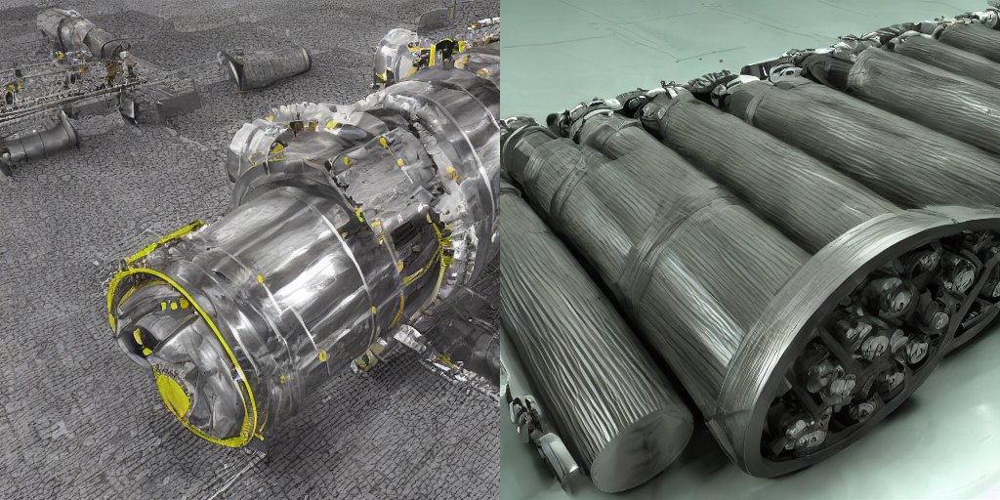

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=1, cols=2)
grid

1000 epochs

In [ ]:


def load_images_from_folder(folder_path):
    images = []
    for filename in os.listdir(folder_path):
        if filename.lower().endswith(('.png')):
            img_path = os.path.join(folder_path, filename)
            img = Image.open(img_path)
            images.append(img)
    return images

# Image grid helper function from HuggingFace
def image_grid(imgs, rows, cols):
    assert len(imgs) == rows*cols

    w, h = imgs[0].size
    grid = Image.new('RGB', size=(cols*w, rows*h))
    grid_w, grid_h = grid.size

    for i, img in enumerate(imgs):
        grid.paste(img, box=(i%cols*w, i//cols*h))
    return grid



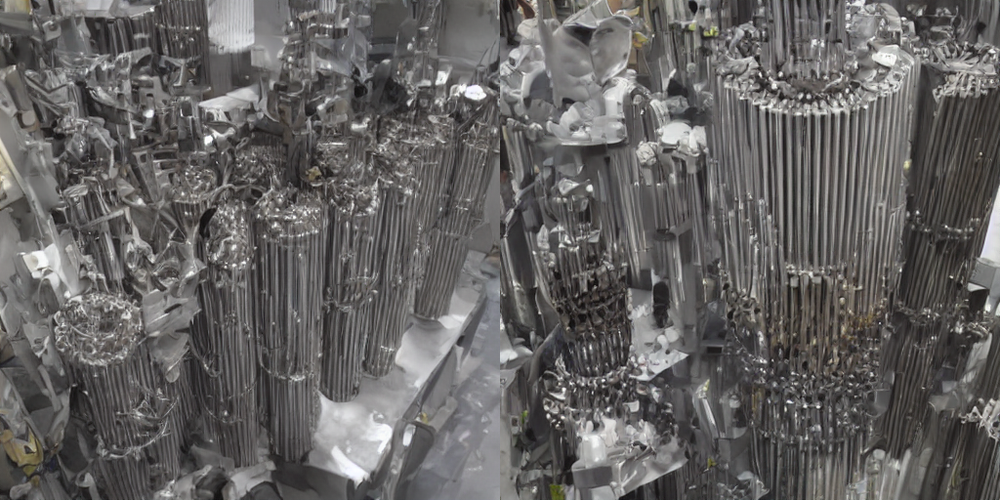

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=1, cols=2)
grid

2000 epochs

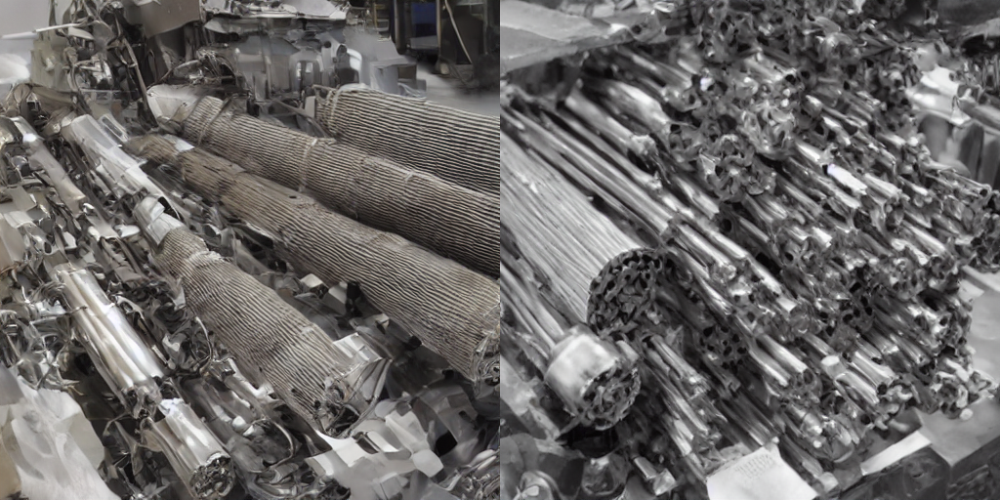

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=1, cols=2)
grid

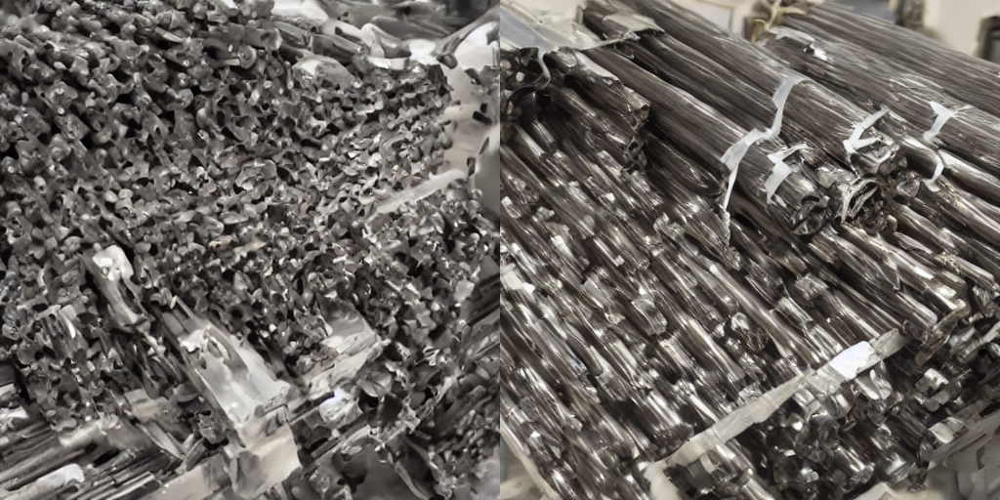

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=1, cols=2)
grid

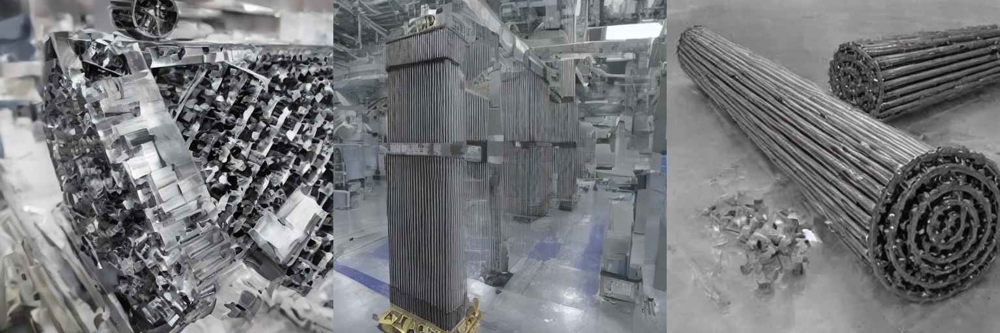

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=1, cols=3)
grid

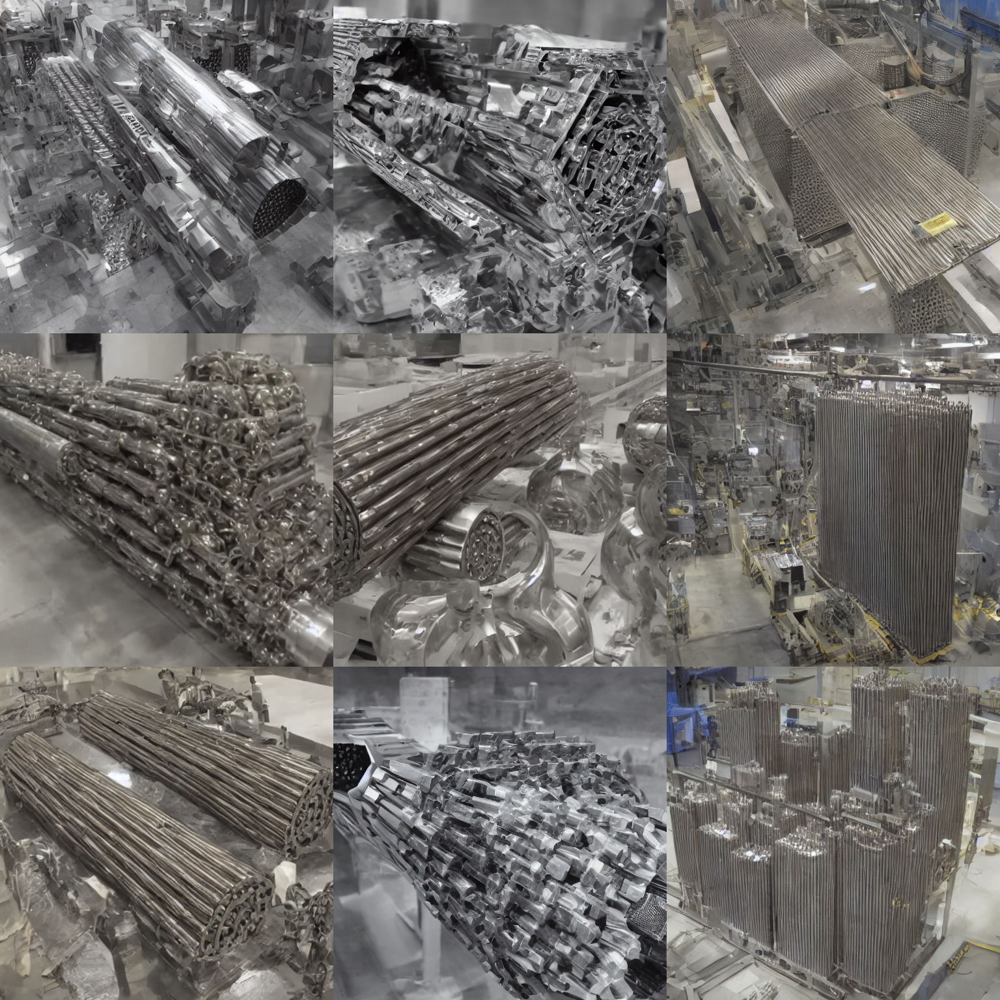

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=3, cols=3)
grid

1000 epochs with augmentation

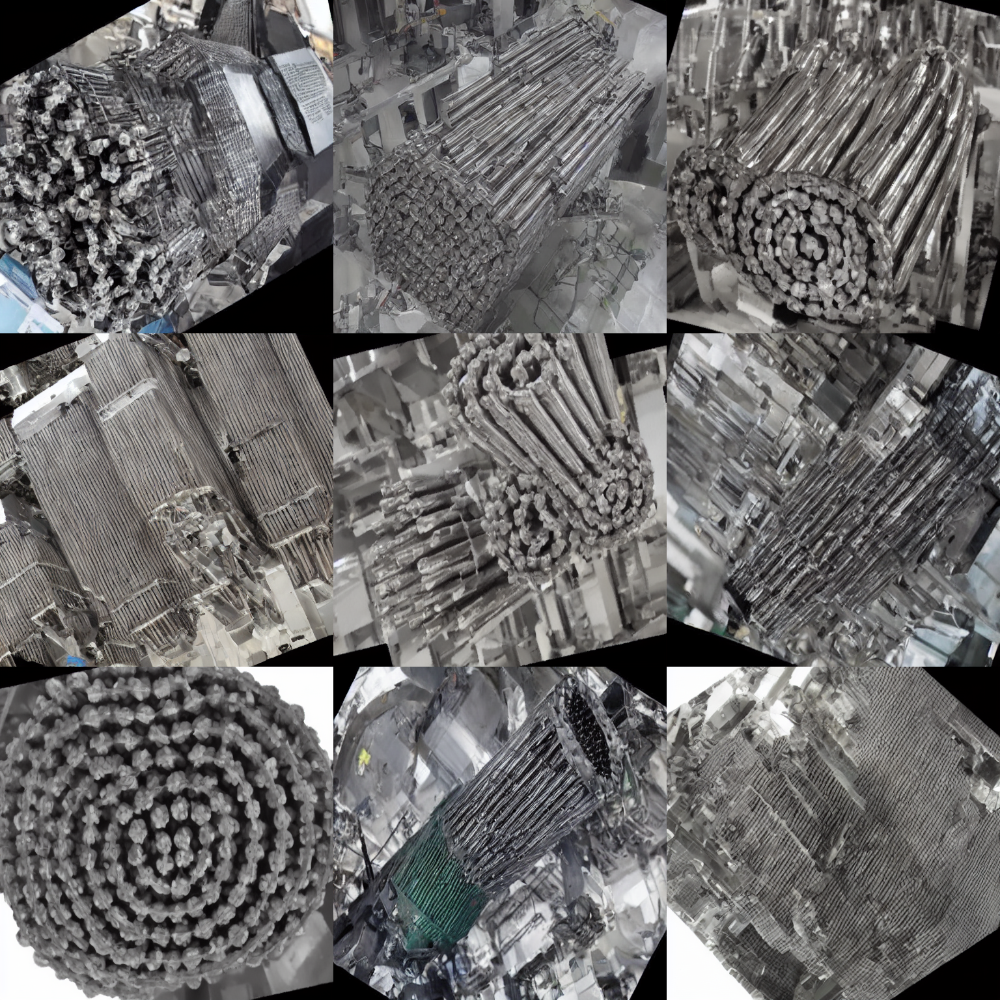

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=3, cols=3)
grid

2000 augmented

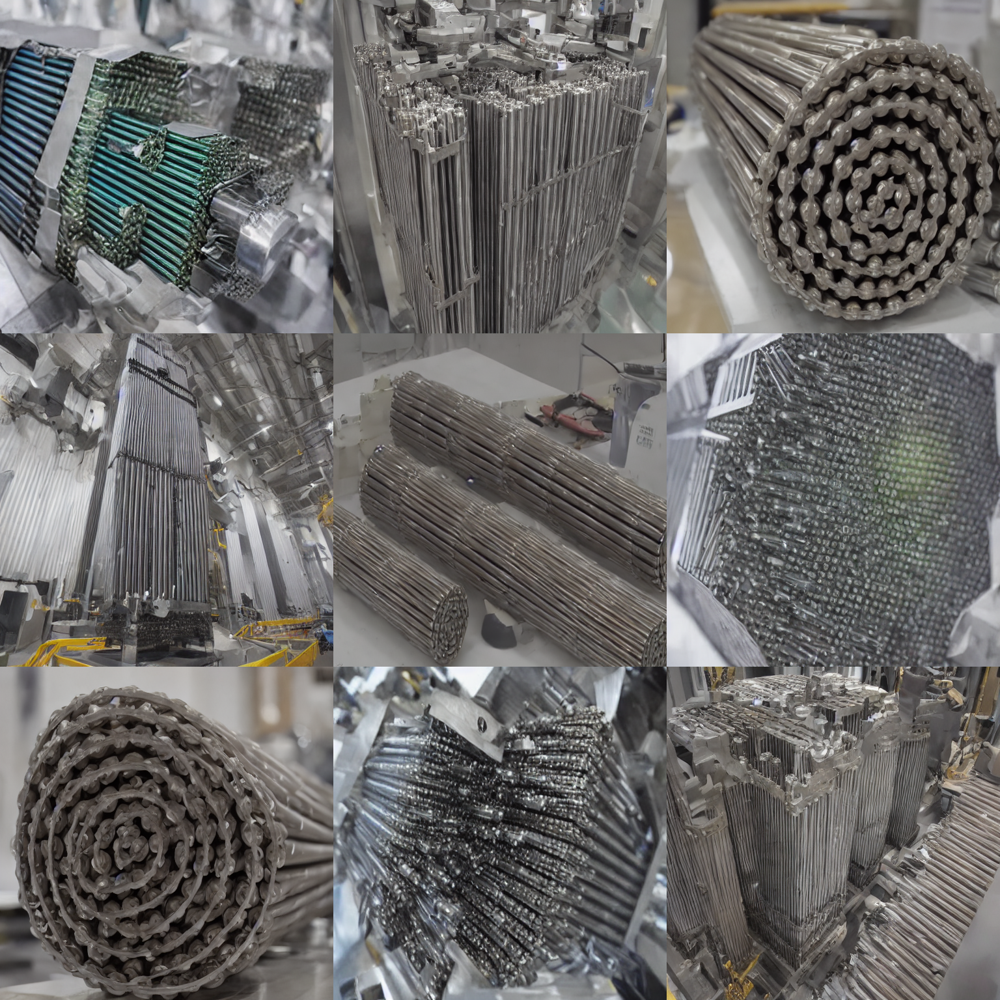

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=3, cols=3)
grid

5000 epochs augmented

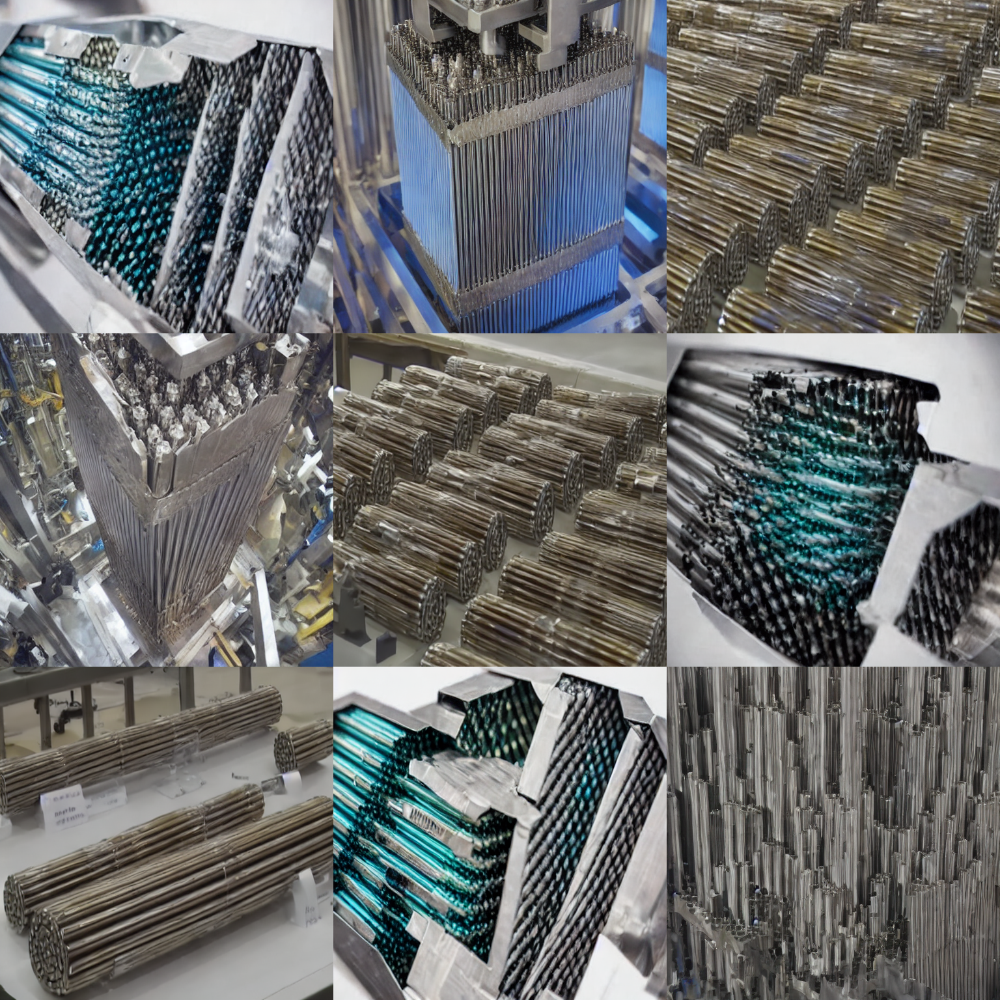

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=3, cols=3)
grid

3000 epochs

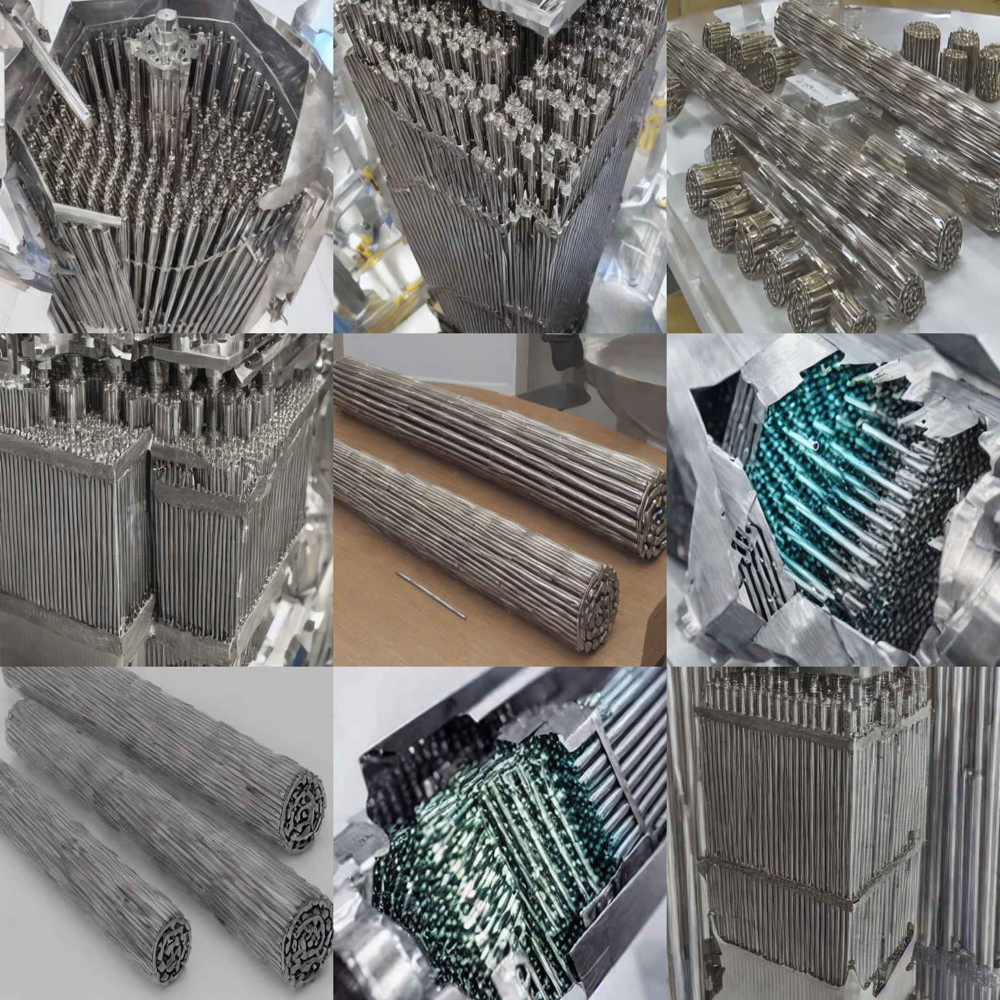

In [ ]:
images = load_images_from_folder("./output_images")
grid = image_grid(images, rows=3, cols=3)
grid

In [ ]:
!zip -r nuclear_fuel_bundle-model-v1-4_augmented_5000_1.zip /content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1

  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/ (stored 0%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/text_encoder/ (stored 0%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/text_encoder/config.json (deflated 45%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/text_encoder/model.safetensors (deflated 8%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/scheduler/ (stored 0%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/scheduler/scheduler_config.json (deflated 41%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/feature_extractor/ (stored 0%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/feature_extractor/preprocessor_config.json (deflated 48%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/unet/ (stored 0%)
  adding: content/nuclear_fuel_bundle-model-v1-4_augmented_5000_1/unet/config.json (deflated 65%)
  addin

In [ ]:
import shutil
from google.colab import files


# Define the name of the zip file
zip_file = 'nuclear_fuel_bundle-model-v1-4_augmented_5000_1.zip'

# Download the zip file
files.download(zip_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>